<a href="https://colab.research.google.com/github/ck3378/GPU-Accelerated-Deep-Learning-Engine/blob/main/ReLU%20Optimization%20and%20Benchmarking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import numpy as np
import torch
import time
import pandas as pd
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


In [2]:

def relu_numpy(x):
    return np.maximum(0, x)

x = np.array([-3, -1, 0, 2, 5], dtype=np.float32)

output = relu_numpy(x)

print("Input:", x)
print("ReLU Output:", output)


Input: [-3. -1.  0.  2.  5.]
ReLU Output: [0. 0. 0. 2. 5.]


In [3]:

x_torch = torch.tensor(
    [-3, -1, 0, 2, 5],
    dtype=torch.float32
)

output_torch = torch.relu(x_torch)

print("PyTorch CPU:", output_torch)


PyTorch CPU: tensor([0., 0., 0., 2., 5.])


In [4]:

x_gpu = x_torch.to(device)

output_gpu = torch.relu(x_gpu)

print("PyTorch GPU:", output_gpu)


PyTorch GPU: tensor([0., 0., 0., 2., 5.], device='cuda:0')


In [5]:

def benchmark_cpu(func, x, iterations=30):

    for _ in range(5):
        func(x)

    start = time.perf_counter()

    for _ in range(iterations):
        func(x)

    end = time.perf_counter()

    return (end - start) / iterations * 1000


def benchmark_gpu(func, x, iterations=30):

    for _ in range(5):
        func(x)

    torch.cuda.synchronize()

    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()

    for _ in range(iterations):
        func(x)

    end.record()
    end.synchronize()

    return start.elapsed_time(end) / iterations


In [6]:

sizes = [
    1_000,
    100_000,
    1_000_000,
    10_000_000,
    50_000_000
]

results = []

for n in sizes:

    print(f"Benchmarking {n:,} elements...")


    x_numpy = np.random.randn(n).astype(np.float32)

    x_cpu = torch.from_numpy(x_numpy)

    x_gpu = x_cpu.to(device)

    iterations = 30 if n <= 1_000_000 else 10

    numpy_time = benchmark_cpu(
        relu_numpy, x_numpy, iterations
    )

    pytorch_cpu_time = benchmark_cpu(
        torch.relu, x_cpu, iterations
    )

    pytorch_gpu_time = benchmark_gpu(
        torch.relu, x_gpu, iterations
    )

    results.append({
        "Input Size": n,
        "NumPy CPU (ms)": numpy_time,
        "PyTorch CPU (ms)": pytorch_cpu_time,
        "PyTorch GPU (ms)": pytorch_gpu_time
    })

benchmark_df = pd.DataFrame(results)

print("\nBenchmark Results:")
display(benchmark_df)


Benchmarking 1,000 elements...
Benchmarking 100,000 elements...
Benchmarking 1,000,000 elements...
Benchmarking 10,000,000 elements...
Benchmarking 50,000,000 elements...

Benchmark Results:


,Input Size,NumPy CPU (ms),PyTorch CPU (ms),PyTorch GPU (ms)
0,1000,0.004143,0.004492,0.033995
1,100000,0.087364,0.013349,0.010923
2,1000000,0.881662,0.355109,0.036752
3,10000000,14.712970,21.572013,0.340256
4,50000000,85.974339,117.965577,1.677722


In [7]:

import torch

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)

try:
    import triton
    import triton.language as tl

    print("Triton version:", triton.__version__)
    print("Triton is ready!")

except ImportError:
    print("Triton is not installed.")


GPU: Tesla T4
CUDA: 13.0
Triton version: 3.8.0
Triton is ready!


In [8]:

import torch
import triton
import triton.language as tl

@triton.jit
def custom_relu_kernel(X, Y, N, BLOCK_SIZE: tl.constexpr):

    pid = tl.program_id(0)

    offsets = pid * BLOCK_SIZE + tl.arange(0, BLOCK_SIZE)

    mask = offsets < N

    x = tl.load(X + offsets, mask=mask, other=0.0)

    y = tl.maximum(x, 0.0)

    tl.store(Y + offsets, y, mask=mask)


def custom_relu(x):

    assert x.is_cuda
    assert x.is_contiguous()

    output = torch.empty_like(x)

    n = x.numel()
    block_size = 256

    grid = (triton.cdiv(n, block_size),)

    custom_relu_kernel[grid](
        x,
        output,
        n,
        BLOCK_SIZE=block_size
    )

    return output


In [9]:

x_test = torch.tensor(
    [-5, -3, -1, 0, 1, 2, 5, 10],
    dtype=torch.float32,
    device="cuda"
)

pytorch_output = torch.relu(x_test)

custom_output = custom_relu(x_test)

print("Input:", x_test)
print("PyTorch output:", pytorch_output)
print("Custom Triton output:", custom_output)

print(
    "Outputs match:",
    torch.allclose(pytorch_output, custom_output)
)


Input: tensor([-5., -3., -1.,  0.,  1.,  2.,  5., 10.], device='cuda:0')
PyTorch output: tensor([ 0.,  0.,  0.,  0.,  1.,  2.,  5., 10.], device='cuda:0')
Custom Triton output: tensor([ 0.,  0.,  0.,  0.,  1.,  2.,  5., 10.], device='cuda:0')
Outputs match: True


In [10]:

sizes = [1000, 100000, 1000000, 10000000, 50000000]

custom_results = []

for n in sizes:

    print(f"Benchmarking {n:,} elements...")

    x = torch.randn(n, device="cuda", dtype=torch.float32)

    iterations = 30 if n <= 1000000 else 10

    pytorch_time = benchmark_gpu(
        torch.relu, x, iterations
    )

    custom_time = benchmark_gpu(
        custom_relu, x, iterations
    )

    custom_results.append({
        "Input Size": n,
        "PyTorch CUDA (ms)": pytorch_time,
        "Custom Triton (ms)": custom_time,
        "Speedup": pytorch_time / custom_time
    })

custom_df = pd.DataFrame(custom_results)

display(custom_df.round(4))


Benchmarking 1,000 elements...
Benchmarking 100,000 elements...
Benchmarking 1,000,000 elements...
Benchmarking 10,000,000 elements...
Benchmarking 50,000,000 elements...


,Input Size,PyTorch CUDA (ms),Custom Triton (ms),Speedup
0,1000,0.0135,0.0434,0.3113
1,100000,0.0142,0.0453,0.3139
2,1000000,0.0366,0.0462,0.7919
3,10000000,0.3411,0.3273,1.0422
4,50000000,1.6786,1.5959,1.0518


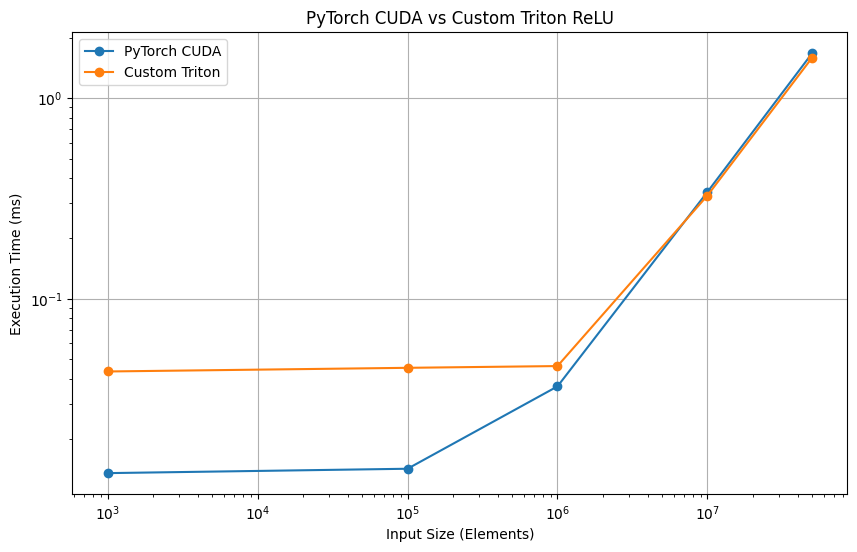

In [11]:

plt.figure(figsize=(10, 6))

plt.plot(
    custom_df["Input Size"],
    custom_df["PyTorch CUDA (ms)"],
    marker="o",
    label="PyTorch CUDA"
)

plt.plot(
    custom_df["Input Size"],
    custom_df["Custom Triton (ms)"],
    marker="o",
    label="Custom Triton"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Input Size (Elements)")
plt.ylabel("Execution Time (ms)")
plt.title("PyTorch CUDA vs Custom Triton ReLU")

plt.legend()
plt.grid(True)
plt.show()


In [12]:

def custom_relu_tuned(x, block_size=256):

    assert x.is_cuda
    assert x.is_contiguous()

    output = torch.empty_like(x)

    n = x.numel()

    grid = (triton.cdiv(n, block_size),)

    custom_relu_kernel[grid](
        x,
        output,
        n,
        BLOCK_SIZE=block_size
    )

    return output


In [13]:

block_sizes = [128, 256, 512, 1024]

input_size = 50_000_000

x = torch.randn(
    input_size,
    device="cuda",
    dtype=torch.float32
)

tuning_results = []

for block in block_sizes:

    print(f"Testing block size: {block}")

    output = custom_relu_tuned(x, block)

    torch.cuda.synchronize()

    assert torch.allclose(output, torch.relu(x))

    execution_time = benchmark_gpu(
        lambda x: custom_relu_tuned(x, block),
        x,
        iterations=30
    )

    bandwidth = (
        input_size * 4 * 2 /
        (execution_time / 1000) / 1e9
    )

    tuning_results.append({
        "Block Size": block,
        "Execution Time (ms)": execution_time,
        "Effective Bandwidth (GB/s)": bandwidth
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df.round(4))


Testing block size: 128
Testing block size: 256
Testing block size: 512
Testing block size: 1024


,Block Size,Execution Time (ms),Effective Bandwidth (GB/s)
0,128,1.6828,237.6964
1,256,1.5832,252.6554
2,512,1.6478,242.7448
3,1024,1.6968,235.7319


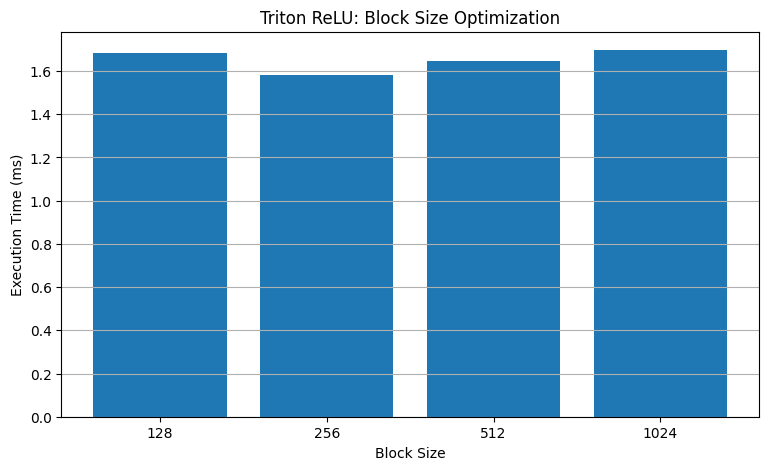

In [14]:

plt.figure(figsize=(9, 5))

plt.bar(
    tuning_df["Block Size"].astype(str),
    tuning_df["Execution Time (ms)"]
)

plt.xlabel("Block Size")
plt.ylabel("Execution Time (ms)")
plt.title("Triton ReLU: Block Size Optimization")
plt.grid(axis="y")
plt.show()


In [15]:

best_config = tuning_df.loc[
    tuning_df["Execution Time (ms)"].idxmin()
]

print("Best block size:", best_config["Block Size"])
print("Execution time:", best_config["Execution Time (ms)"], "ms")
print("Effective bandwidth:", best_config["Effective Bandwidth (GB/s)"], "GB/s")


Best block size: 256.0
Execution time: 1.583184051513672 ms
Effective bandwidth: 252.65540012076463 GB/s


In [16]:

import torch
import shutil

from torch.utils.cpp_extension import CUDA_HOME

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA Toolkit:", CUDA_HOME)
print("NVCC compiler:", shutil.which("nvcc"))

if CUDA_HOME is not None and shutil.which("nvcc") is not None:
    print("Ready to compile native CUDA C++!")
else:
    print("CUDA compiler toolkit needs attention.")


GPU: Tesla T4
PyTorch CUDA: 13.0
CUDA Toolkit: /usr/local/cuda
NVCC compiler: /usr/local/cuda/bin/nvcc
Ready to compile native CUDA C++!


In [18]:

!nvidia-smi
!nvcc --version


Tue Nov 10 03:13:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             29W /   70W |    2143MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [20]:

!pip install ninja


In [21]:
import ninja

In [25]:

import shutil
import os

build_dir = "/root/.cache/torch_extensions/py313_cu130/relu_cuda_extension"

if os.path.exists(build_dir):
    shutil.rmtree(build_dir)

print("Old build directory cleared.")


Old build directory cleared.


In [32]:

cpp_source = """
#include <torch/extension.h>

torch::Tensor relu_cuda(torch::Tensor input);
"""

relu_cuda_ext = load_inline(
    name="relu_cuda_extension_v3",
    cpp_sources=cpp_source,
    cuda_sources=cuda_source,
    functions=["relu_cuda"],
    with_cuda=True,
    extra_cflags=["-O3"],
    extra_cuda_cflags=["-O3"],
    verbose=True
)

print("Native CUDA ReLU compiled successfully!")


Native CUDA ReLU compiled successfully!


In [33]:

import torch

x_test = torch.tensor(
    [-5.0, -3.0, -1.0, 0.0, 1.0, 2.0, 5.0, 10.0],
    device="cuda"
)

pytorch_output = torch.relu(x_test)

native_output = relu_cuda_ext.relu_cuda(x_test)

print("Input:        ", x_test)
print("PyTorch ReLU: ", pytorch_output)
print("Native CUDA:  ", native_output)

print("\nCorrectness:", torch.allclose(pytorch_output, native_output))


Input:         tensor([-5., -3., -1.,  0.,  1.,  2.,  5., 10.], device='cuda:0')
PyTorch ReLU:  tensor([ 0.,  0.,  0.,  0.,  1.,  2.,  5., 10.], device='cuda:0')
Native CUDA:   tensor([ 0.,  0.,  0.,  0.,  1.,  2.,  5., 10.], device='cuda:0')

Correctness: True


In [34]:

import pandas as pd
import torch

input_sizes = [
    1_000,
    100_000,
    1_000_000,
    10_000_000,
    50_000_000
]

# Use the best block size from your Triton tuning.
# If tuning is not finished, use 256 for now.
best_block_size = 256

def benchmark_native(func, x, iterations=50):
    for _ in range(10):
        func(x)

    torch.cuda.synchronize()

    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)

    start.record()

    for _ in range(iterations):
        func(x)

    end.record()
    end.synchronize()

    return start.elapsed_time(end) / iterations


results = []

for n in input_sizes:

    x = torch.randn(n, device="cuda", dtype=torch.float32)

    # PyTorch CUDA
    pytorch_time = benchmark_native(
        lambda x: torch.relu(x), x
    )

    # Triton
    triton_time = benchmark_native(
        lambda x: custom_relu_tuned(x, best_block_size), x
    )

    # Native CUDA C++
    native_time = benchmark_native(
        lambda x: relu_cuda_ext.relu_cuda(x), x
    )

    # Verify correctness
    expected = torch.relu(x)

    assert torch.allclose(expected, custom_relu_tuned(x, best_block_size))
    assert torch.allclose(expected, relu_cuda_ext.relu_cuda(x))

    results.append({
        "Input Size": n,
        "PyTorch CUDA (ms)": pytorch_time,
        "Triton (ms)": triton_time,
        "Native CUDA (ms)": native_time
    })

benchmark_df = pd.DataFrame(results)

display(benchmark_df.round(4))


,Input Size,PyTorch CUDA (ms),Triton (ms),Native CUDA (ms)
0,1000,0.0185,0.0537,0.0078
1,100000,0.0115,0.0324,0.0078
2,1000000,0.0365,0.0357,0.0379
3,10000000,0.3377,0.3189,0.3401
4,50000000,1.6736,1.5845,1.6054


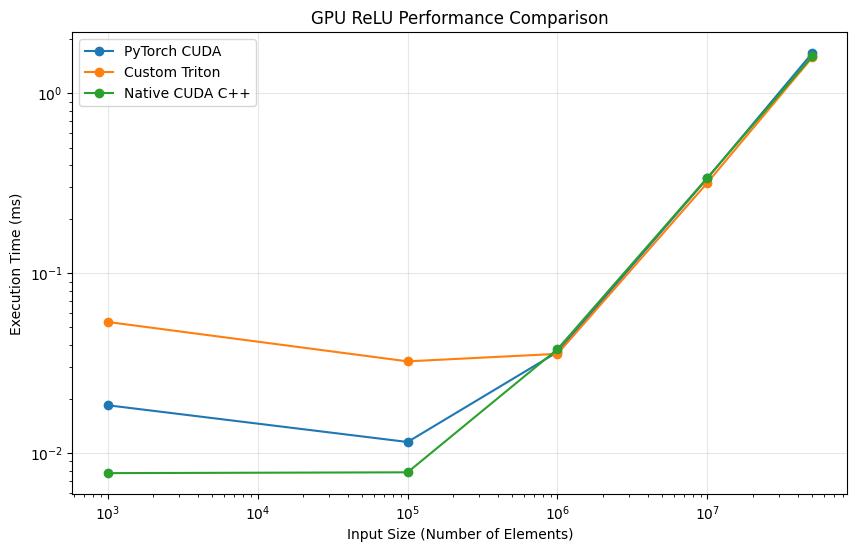

In [35]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    benchmark_df["Input Size"],
    benchmark_df["PyTorch CUDA (ms)"],
    marker="o",
    label="PyTorch CUDA"
)

plt.plot(
    benchmark_df["Input Size"],
    benchmark_df["Triton (ms)"],
    marker="o",
    label="Custom Triton"
)

plt.plot(
    benchmark_df["Input Size"],
    benchmark_df["Native CUDA (ms)"],
    marker="o",
    label="Native CUDA C++"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Input Size (Number of Elements)")
plt.ylabel("Execution Time (ms)")
plt.title("GPU ReLU Performance Comparison")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()
